9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 136s 106ms/step - accuracy: 0.4163 - loss: 1.6365 - val_accuracy: 0.4607 - val_loss: 1.5314
Epoch 2/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 124s 99ms/step - accuracy: 0.4881 - loss: 1.4513 - val_accuracy: 0.4597 - val_loss: 1.5115
Epoch 3/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 126s 101ms/step - accuracy: 0.5041 - loss: 1.3963 - val_accuracy: 0.5083 - val_loss: 1.4052
Epoch 4/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 126s 101ms/step - accuracy: 0.5189 - loss: 1.3606 - val_accuracy: 0.5028 - val_loss: 1.4069
Epoch 5/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 140s 100ms/step - accuracy: 0.5265 - loss: 1.3364 - val_accuracy: 0.5112 - val_loss: 1.4014
313/313 ━━━━━━━━━━━━━━━━━━━━ 23s 75ms/step - accuracy: 0.5028 - loss: 1.4134
Test Accuracy: 50.279998779296875 %
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
Actual: cat
Predicted: frog
Training Accuracy: 52.65499949455261 %
Validation Accuracy: 51.12000107765198 %
Test Accuracy: 50.279998779296

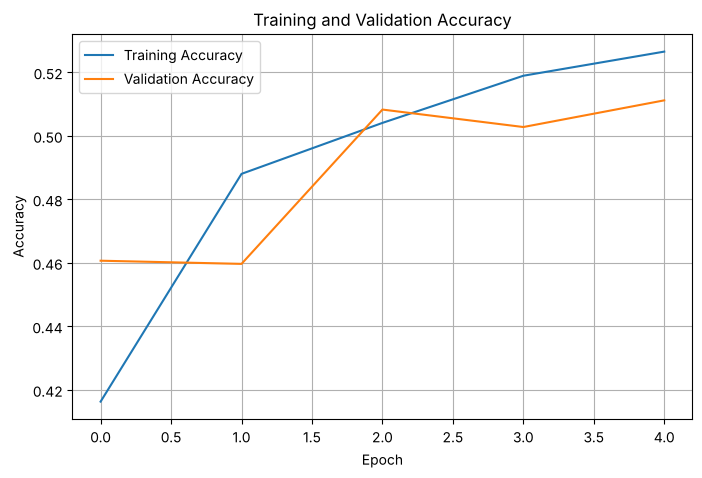

In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

y_train = y_train.flatten()
y_test = y_test.flatten()

x_train = tf.image.resize(x_train, (96, 96))
x_test = tf.image.resize(x_test, (96, 96))

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(96, 96, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

model = tf.keras.Sequential([
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.2
)

loss, accuracy = model.evaluate(x_test, y_test)
print("Test Accuracy:", accuracy * 100, "%")

prediction = model.predict(x_test[:1])

classes = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

predicted_class = np.argmax(prediction)

print("Actual:", classes[y_test[0]])
print("Predicted:", classes[predicted_class])

train_accuracy = history.history["accuracy"][-1]
val_accuracy = history.history["val_accuracy"][-1]

print("Training Accuracy:", train_accuracy * 100, "%")
print("Validation Accuracy:", val_accuracy * 100, "%")

loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)

print("Test Accuracy:", test_accuracy * 100, "%")

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid()
plt.show()